In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
logs = [
    '/data/models/bin/reference_logs/resnet18_20260105_201712/',
    '/data/models/bin/reference_logs/swin_tiny_20260115_132240/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_20260205_233727/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260206_130501/',
]
labels = ['resnet18_old', 'swin_old', 'swin_new', 'swin_optim']

resnet18_old -- Train Min: (0.2556). Val Min: (1.2952)
swin_old -- Train Min: (0.1383). Val Min: (1.1511)
swin_new -- Train Min: (0.2841). Val Min: (1.2132)
swin_optim -- Train Min: (0.8547). Val Min: (1.3824)


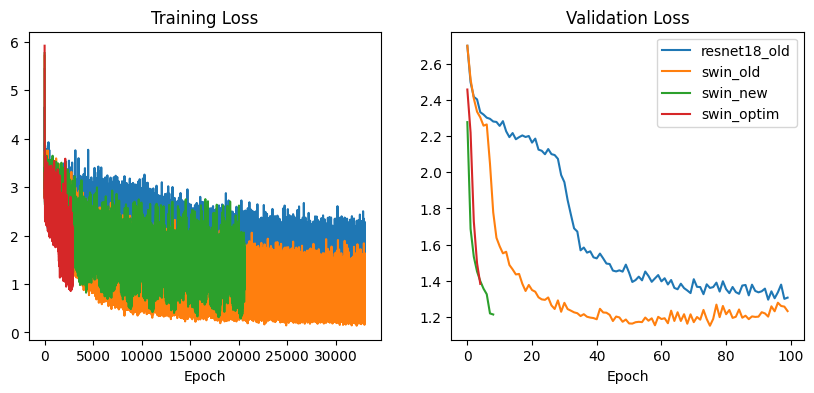

In [5]:
fig, axs = plt.subplots(1,2, figsize=(10,4))
for i, log in enumerate(logs):
    loss = np.load(log+'loss_log.pkl', allow_pickle=True)
    train = np.stack(loss['train'])
    val = np.stack(loss['val'])
    if '2026_pathway_generation' in log:
        train = train[:,2]
        val = val[:,2]
    print(f'{labels[i]} -- Train Min: ({round(np.min(train), 4)}). Val Min: ({round(np.min(val), 4)})')
    axs[0].plot(train, label=labels[i])
    axs[0].set_title('Training Loss')
    axs[0].set_xlabel('Epoch')
    axs[1].plot(val, label=labels[i])
    axs[1].set_title('Validation Loss')
    axs[1].set_xlabel('Epoch')
    plt.legend()
pass

In [ ]:
log = '/data/models/bin/reference_logs/resnet18_20260105_201712/'
# log = '/data/models/bin/2026_pathway_generation/reference_logs/resnet18_ddp_graph_4_20260205_141333/'
loss = np.load(log+'loss_log.pkl', allow_pickle=True)
train = np.stack(loss['train'])
val = np.stack(loss['val'])